Learning objectives
- Understand decision trees, nodes, branches, and leaves.
- Learn how a tree chooses splits using Gini impurity.
- Train your first decision-tree classifier on AAPL features.
- Compare it against your majority baseline and logistic regression.
- Investigate overfitting using different tree depths.
- Select a model using validation data and preserve the final test set.

In [1]:
#Imports and Configuration
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    brier_score_loss,
    confusion_matrix
)

RANDOM_STATE = 42
DATA_PATH = "../data/raw/AAPL_daily_raw.csv"

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)

In [11]:
# Loading AAPL dataset
df = pd.read_csv(DATA_PATH, index_col=0)

# Parse timestamps with mixed timezone offsets consistently
df.index = pd.to_datetime(df.index, errors="raise", utc=True)

# Remove timezone information after normalizing to UTC
df.index = df.index.tz_localize(None)

# Sort dates chronologically
df = df.sort_index()
df.index.name = "Date"

print("Shape:", df.shape)
print("Index type:", type(df.index))
print("Index dtype:", df.index.dtype)
print("Date range:", df.index.min(), "to", df.index.max())
print("Columns:", df.columns.tolist())

display(df.head())

Shape: (2766, 9)
Index type: <class 'pandas.DatetimeIndex'>
Index dtype: datetime64[us]
Date range: 2015-01-02 05:00:00 to 2025-12-31 05:00:00
Columns: ['Open', 'High', 'Low', 'Close', 'Adj Close', 'Volume', 'Dividends', 'Stock Splits', 'daily_return']


,Open,High,Low,Close,Adj Close,Volume,Dividends,Stock Splits,daily_return
Date,,,,,,,,,
2015-01-02 05:00:00,27.847500,27.860001,26.837500,27.332500,24.171755,212818400,0.0,0.0,NaN
2015-01-05 05:00:00,27.072500,27.162500,26.352501,26.562500,23.490799,257142000,0.0,0.0,-0.028172
2015-01-06 05:00:00,26.635000,26.857500,26.157499,26.565001,23.493013,263188400,0.0,0.0,0.000094
2015-01-07 05:00:00,26.799999,27.049999,26.674999,26.937500,23.822430,160423600,0.0,0.0,0.014022
2015-01-08 05:00:00,27.307501,28.037500,27.174999,27.972500,24.737757,237458000,0.0,0.0,0.038423


In [19]:
#Creating Features and prediction target
df = df.copy()

df["return_1d"] = df["Adj Close"].pct_change()
df["return_5d"] = df["Adj Close"].pct_change(5)
df["return_10d"] = df["Adj Close"].pct_change(10)

df["sma_20"] = df["Adj Close"].rolling(20).mean()
df["sma_50"] = df["Adj Close"].rolling(50).mean()
df["price_to_sma20"] = df["Adj Close"] / df["sma_20"] - 1
df["price_to_sma50"] = df["Adj Close"] / df["sma_50"] - 1

df["volatility_20d"] = df["return_1d"].rolling(20).std()
df["momentum_10d"] = df["Adj Close"].pct_change(10)

df["volume_avg_20d"] = df["Volume"].rolling(20).mean()
df["relative_volume"] = df["Volume"] / df["volume_avg_20d"]

# Label: next trading day's direction
df["future_return_1d"] = df["Adj Close"].shift(-1) / df["Adj Close"] - 1
df["target_up"] = (df["future_return_1d"] > 0).astype(int)

FEATURES = [
    "return_1d",
    "return_5d",
    "return_10d",
    "price_to_sma20",
    "price_to_sma50",
    "volatility_20d",
    "momentum_10d",
    "relative_volume"
]

model_df = df[FEATURES + ["future_return_1d", "target_up"]].dropna().copy()

X = model_df[FEATURES]
y = model_df["target_up"].astype(int)

print("Rows:", len(model_df))
print("Features:", len(FEATURES))
display(y.value_counts().rename(index={0: "DOWN", 1: "UP"}))

Rows: 2716
Features: 8


target_up
UP      1438
DOWN    1278
Name: count, dtype: int64

In [15]:
#Splittting the dataset 
n = len(model_df)

train_end = int(n * 0.70)
val_end = int(n * 0.85)

# Leave one row between partitions for the one-day-ahead target.
train_idx = np.arange(0, train_end - 1)
val_idx = np.arange(train_end, val_end - 1)
test_idx = np.arange(val_end, n)

X_train, y_train = X.iloc[train_idx], y.iloc[train_idx]
X_val, y_val = X.iloc[val_idx], y.iloc[val_idx]
X_test, y_test = X.iloc[test_idx], y.iloc[test_idx]

for name, X_part, y_part in [
    ("Train", X_train, y_train),
    ("Validation", X_val, y_val),
    ("Test", X_test, y_test)
]:
    print(
        f"{name}: {X_part.index.min().date()} to "
        f"{X_part.index.max().date()} | rows={len(X_part)}"
    )

assert X_train.index.max() < X_val.index.min()
assert X_val.index.max() < X_test.index.min()
assert "future_return_1d" not in X.columns
assert "target_up" not in X.columns
assert np.isfinite(X.to_numpy()).all()

print("Chronological split and feature checks passed.")

Train: 2015-03-16 to 2022-09-28 | rows=1900
Validation: 2022-09-30 to 2024-05-13 | rows=406
Test: 2024-05-15 to 2025-12-30 | rows=408
Chronological split and feature checks passed.


In [28]:
#Training the First Decision Tree
tree_model = DecisionTreeClassifier(
    criterion="gini",
    max_depth=3,
    min_samples_leaf=20,
    random_state=RANDOM_STATE
)

tree_model.fit(X_train, y_train)

print("Tree trained.")
print("Tree depth:", tree_model.get_depth())
print("Number of leaves:", tree_model.get_n_leaves())
print("Training rows:", len(X_train))

Tree trained.
Tree depth: 3
Number of leaves: 7
Training rows: 1900


In [29]:
#Evaluating Training vs Validating Performance
def evaluate_classifier(model, X_data, y_true, threshold=0.50):
    probabilities = model.predict_proba(X_data)[:, 1]
    predictions = (probabilities >= threshold).astype(int)

    return {
        "accuracy": accuracy_score(y_true, predictions),
        "balanced_accuracy": balanced_accuracy_score(y_true, predictions),
        "precision_up": precision_score(
            y_true, predictions, zero_division=0
        ),
        "recall_up": recall_score(
            y_true, predictions, zero_division=0
        ),
        "macro_f1": f1_score(
            y_true, predictions,
            average="macro", zero_division=0
        ),
        "roc_auc": (
            roc_auc_score(y_true, probabilities)
            if pd.Series(y_true).nunique() == 2
            else np.nan
        ),
        "brier_score": brier_score_loss(y_true, probabilities)
    }


tree_comparison = pd.DataFrame([
    {
        "partition": "Train",
        **evaluate_classifier(tree_model, X_train, y_train)
    },
    {
        "partition": "Validation",
        **evaluate_classifier(tree_model, X_val, y_val)
    }
]).set_index("partition")

display(tree_comparison.round(4))

,accuracy,balanced_accuracy,precision_up,recall_up,macro_f1,roc_auc,brier_score
partition,,,,,,,
Train,0.5668,0.5518,0.5560,0.8624,0.5112,0.5582,0.2429
Validation,0.5296,0.5185,0.5285,0.8381,0.4691,0.5240,0.2516


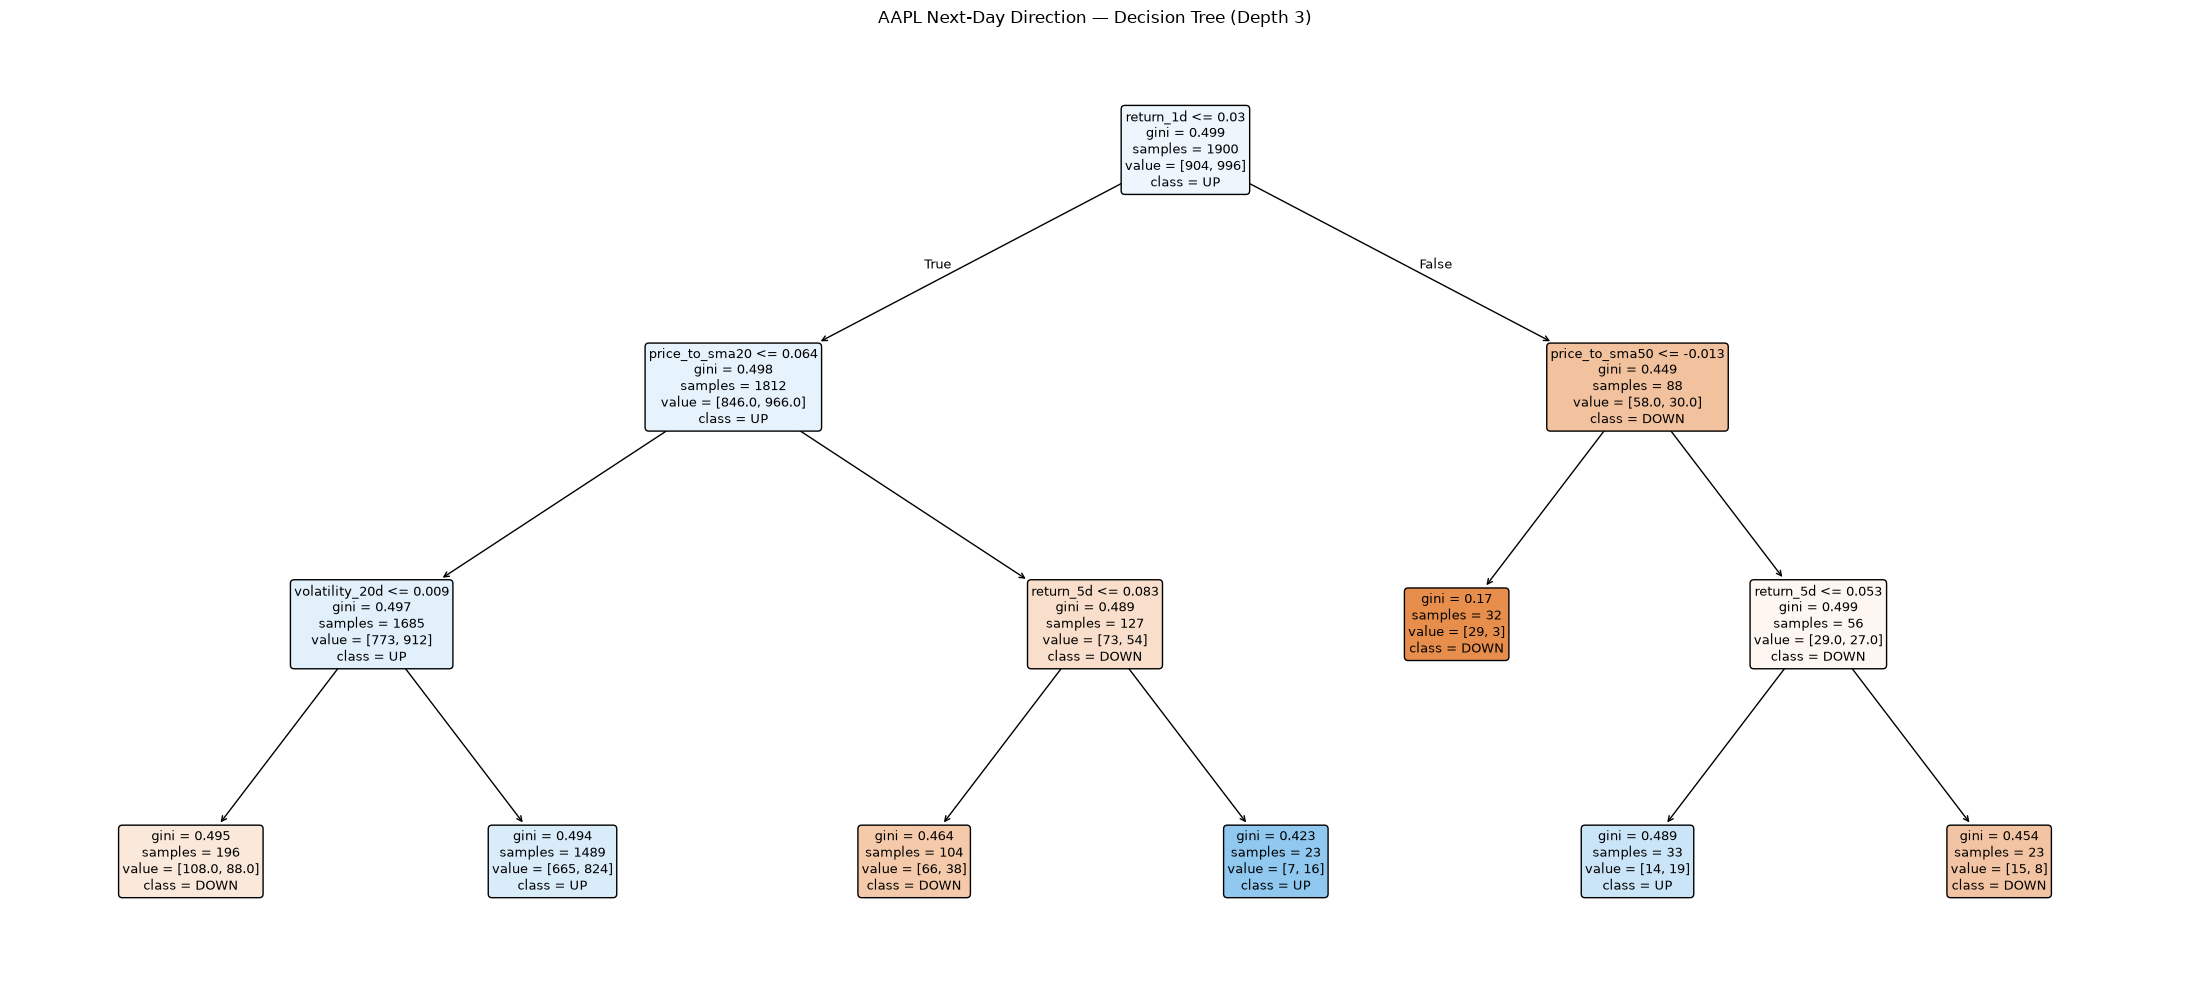

In [30]:
#Visualizing the tree
plt.figure(figsize=(22, 10))

plot_tree(
    tree_model,
    feature_names=FEATURES,
    class_names=["DOWN", "UP"],
    filled=True,
    rounded=True,
    proportion=False,
    impurity=True,
    fontsize=9
)

plt.title("AAPL Next-Day Direction — Decision Tree (Depth 3)")
plt.tight_layout()
plt.show()

In [31]:
#Testing different tree depths 
depth_values = [1, 2, 3, 5, 10, None]
depth_rows = []
depth_models = {}

for depth in depth_values:
    candidate = DecisionTreeClassifier(
        criterion="gini",
        max_depth=depth,
        min_samples_leaf=20,
        random_state=RANDOM_STATE
    )

    candidate.fit(X_train, y_train)
    depth_models[depth] = candidate

    train_metrics = evaluate_classifier(candidate, X_train, y_train)
    val_metrics = evaluate_classifier(candidate, X_val, y_val)

    depth_rows.append({
        "max_depth": str(depth),
        "actual_depth": candidate.get_depth(),
        "leaves": candidate.get_n_leaves(),
        "train_balanced_accuracy": train_metrics["balanced_accuracy"],
        "val_balanced_accuracy": val_metrics["balanced_accuracy"],
        "train_macro_f1": train_metrics["macro_f1"],
        "val_macro_f1": val_metrics["macro_f1"]
    })

depth_results = pd.DataFrame(depth_rows)
display(depth_results.round(4))

,max_depth,actual_depth,leaves,train_balanced_accuracy,val_balanced_accuracy,train_macro_f1,val_macro_f1
0,1,1,2,0.5170,0.4937,0.4025,0.3589
1,2,2,4,0.5303,0.4997,0.4572,0.3876
2,3,3,7,0.5518,0.5185,0.5112,0.4691
3,5,5,15,0.5692,0.5000,0.5343,0.4603
4,10,10,47,0.6415,0.5252,0.6413,0.5245
5,None,17,69,0.6893,0.5320,0.6896,0.5318


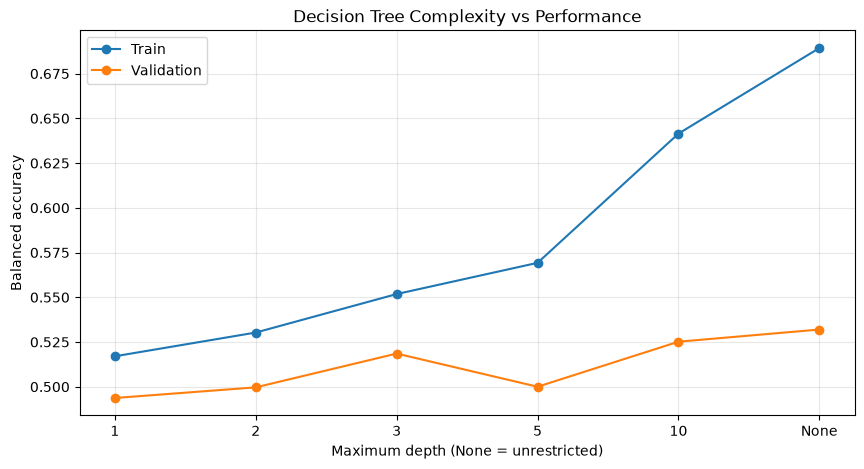

In [32]:
#Plot the train and validation results
plot_data = depth_results.copy()
plot_data["max_depth"] = plot_data["max_depth"].astype(str)

plt.figure(figsize=(10, 5))

plt.plot(
    plot_data["max_depth"],
    plot_data["train_balanced_accuracy"],
    marker="o",
    label="Train"
)

plt.plot(
    plot_data["max_depth"],
    plot_data["val_balanced_accuracy"],
    marker="o",
    label="Validation"
)

plt.xlabel("Maximum depth (None = unrestricted)")
plt.ylabel("Balanced accuracy")
plt.title("Decision Tree Complexity vs Performance")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [33]:
#Selecting tree depth using validation data
best_depth_row = depth_results.loc[
    depth_results["val_balanced_accuracy"].idxmax()
]

best_depth_label = best_depth_row["max_depth"]
best_depth = None if best_depth_label == "None" else int(best_depth_label)

best_tree = depth_models[best_depth]

print("Selected max_depth:", best_depth)
print("Actual tree depth:", best_tree.get_depth())
print("Number of leaves:", best_tree.get_n_leaves())
print(
    "Validation balanced accuracy:",
    round(best_depth_row["val_balanced_accuracy"], 4)
)

Selected max_depth: None
Actual tree depth: 17
Number of leaves: 69
Validation balanced accuracy: 0.532
